In [1]:
import numpy as np
import cv2 
import matplotlib.pyplot as plt
import sys
sys.path.append('./FUNCIONES')
sys.path.append("imagenesEntrada")

# Práctica 4 Manipulación de contraste en imágenes digitales: operaciones locales y globales basadas en procesamiento de histograma 

## Parte 0 Carga de datos

(np.float64(-0.5), np.float64(224.5), np.float64(199.5), np.float64(-0.5))

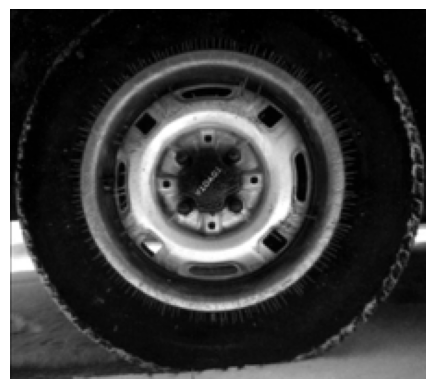

In [2]:
PATH = "imagenesEntrada/img.png"
img = cv2.imread(PATH)


I = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

plt.imshow(I, cmap="gray", vmin=0, vmax=255)
plt.axis("off")

## Primera Parte. Manipulación de contraste mediante transformaciones locales.

1. Utilizando como entrada la imagen img.png facilitada, obtener distintas imágenes de
salida resultados de la aplicación de las siguientes transformaciones locales de
manipulación de contraste:

− Amplitud de Contraste aplicada como una función lineal definida a trozos que
aumente el contraste en la parte baja del histograma. La transformación se compone de
dos funciones lineales definidas por los puntos (p,q) = { (0,0), (50,200), (255,255) },
donde p y q denotan el nivel de gris de entrada y salida, respectivamente.


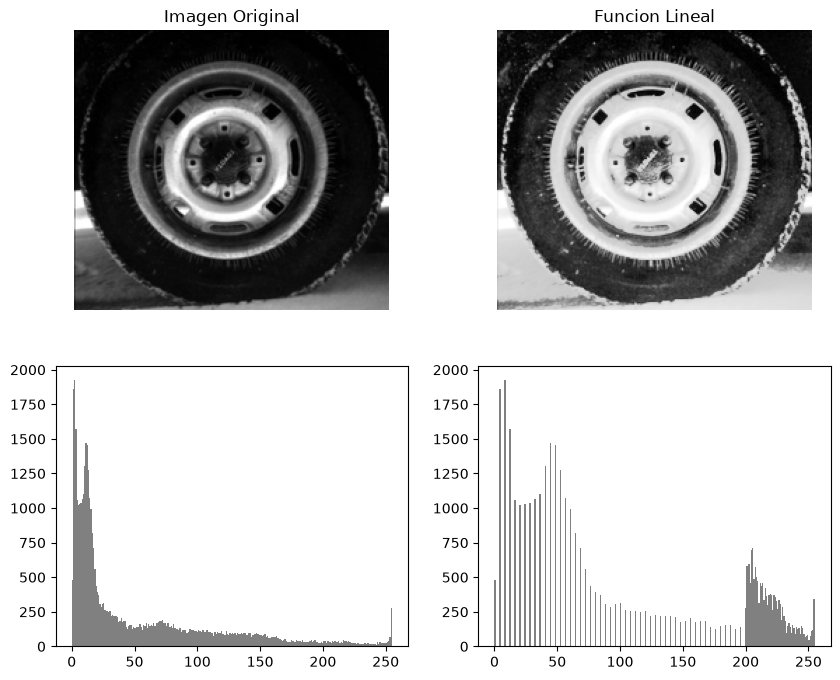

In [3]:

def funcion_lineal(I ,p1, q1, p2, q2):
    m = (q2 - q1) / (p2 - p1)
    n = q1 - m * p1
    return m * I  + n

I1 = I.copy().astype(np.float32)

m1 = I < 51
m2 = I > 50

I1[m1] = funcion_lineal(I[m1], 0, 0, 50, 200)
I1[m2] = funcion_lineal(I[m2], 50, 200, 255, 255)

I1 = np.round(I1).astype(np.uint8)

plt.figure(figsize=(10,8))
plt.subplot(2, 2, 1)
plt.imshow(I, cmap="gray", vmin= 0, vmax=255)
plt.title("Imagen Original")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(I1, cmap="gray", vmin= 0, vmax=255)
plt.title("Funcion Lineal")
plt.axis("off")

plt.subplot(2,2,3)
plt.hist(I.ravel(), bins=256, range=(0,255), color="gray")


plt.subplot(2,2,4)
plt.hist(I1.ravel(), bins=256, range=(0,255), color="gray")

plt.show()




Esta funcion lineal en tramos tiene como objetivo aclarar los pixeles mas claros, y los claros los mantiene claros, como podemos observar ahora vemos detalles en los neumáticos de su relieve que antes eran mas imperceptibles

− Funciones Cuadrada y Cúbica

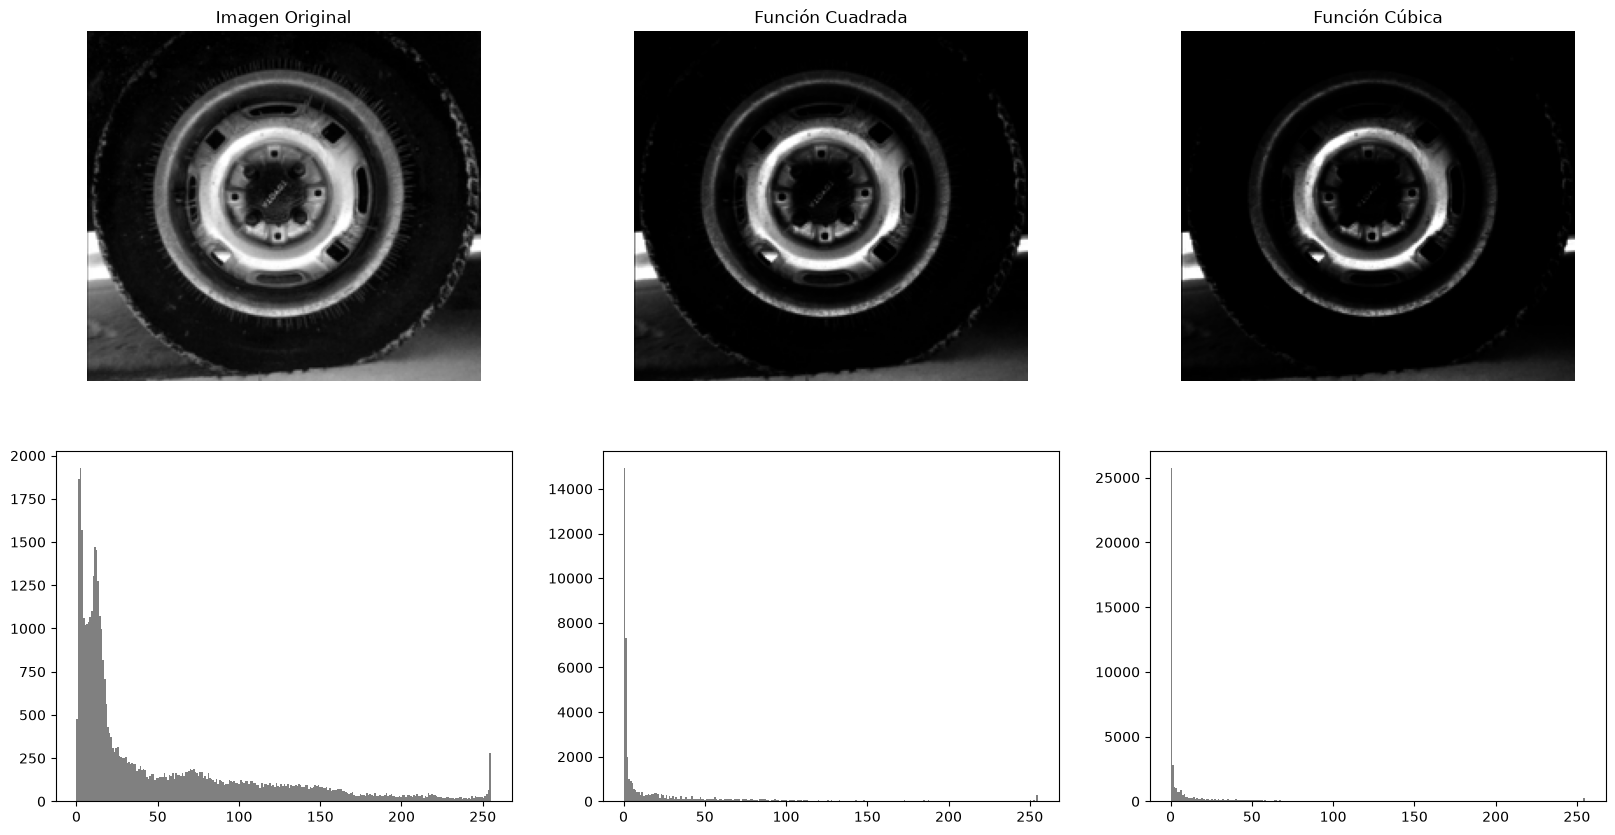

In [4]:


I_norm = I.astype(np.float32) / 255

Icuadrada = np.round(255 * I_norm**2).astype(np.uint8)
Icubica   = np.round(255 * I_norm**3).astype(np.uint8)

plt.figure(figsize=(20,10))
plt.subplot(2, 3, 1)
plt.imshow(I, cmap="gray", vmin= 0, vmax=255)
plt.title("Imagen Original")
plt.axis("off")

plt.subplot(2, 3, 2)
plt.imshow(Icuadrada, cmap="gray", vmin= 0, vmax=255)
plt.title("Función Cuadrada")
plt.axis("off")

plt.subplot(2, 3, 3)
plt.imshow(Icubica, cmap="gray", vmin= 0, vmax=255)
plt.title("Función Cúbica")
plt.axis("off")

plt.subplot(2, 3, 4)
plt.hist(I.ravel(), bins=256, range=(0,255), color="gray")

plt.subplot(2, 3, 5)
plt.hist(Icuadrada.ravel(), bins=256, range=(0,255), color="gray")

plt.subplot(2, 3, 6)
plt.hist(Icubica.ravel(), bins=256, range=(0,255), color="gray")
plt.show()




El objetivo es aumentar el constrante en las zonas claras de la imagen a costa de las oscuras.

Al elevar a una potencia mayor que 1 los valores bajos se aplastan hacia el 0 y los altos se mantienen separados. Como vemos en el resultado las zonas claras se diferencian claramente de las oscuras.

Cuanto mas eleves pues mas aplanas las sombras oscureciendo aun mas partes de la imagen

− Funciones Raíz Cuadrada y Raíz Cúbica.

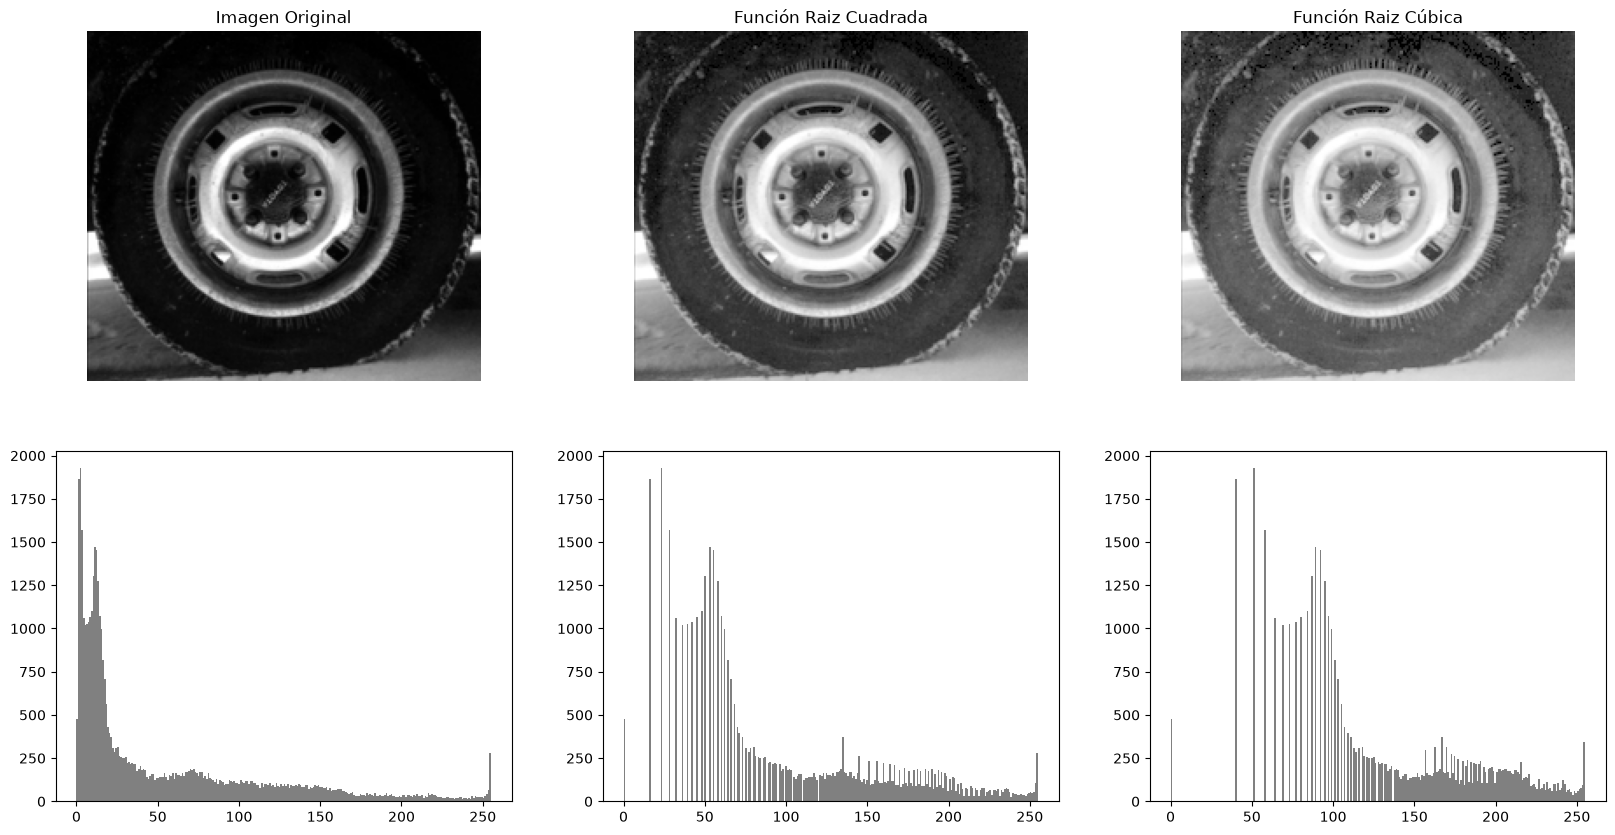

In [5]:
I_norm = I.astype(np.float32) / 255

Ircuadrada = np.round(255 * I_norm**(1/2)).astype(np.uint8)
Ircubica   = np.round(255 * I_norm**(1/3)).astype(np.uint8)

plt.figure(figsize=(20,10))
plt.subplot(2, 3, 1)
plt.imshow(I, cmap="gray", vmin= 0, vmax=255)
plt.title("Imagen Original")
plt.axis("off")

plt.subplot(2, 3, 2)
plt.imshow(Ircuadrada, cmap="gray", vmin= 0, vmax=255)
plt.title("Función Raiz Cuadrada")
plt.axis("off")

plt.subplot(2, 3, 3)
plt.imshow(Ircubica, cmap="gray", vmin= 0, vmax=255)
plt.title("Función Raiz Cúbica")
plt.axis("off")


plt.subplot(2, 3, 4)
plt.hist(I.ravel(), bins=256, range=(0,255), color="gray")

plt.subplot(2, 3, 5)
plt.hist(Ircuadrada.ravel(), bins=256, range=(0,255), color="gray")

plt.subplot(2, 3, 6)
plt.hist(Ircubica.ravel(), bins=256, range=(0,255), color="gray")
plt.show()

El objetivo es aumentar el contraste de las zonas oscuras a costa de las claras.
Al elevar a 1/2 o a 1/3 los valores bajos se expanden y los altos se comprimen.
Como resultado los neumáticos se aclaran y los blancos son mas blancos

Funciones Sigmoide (con α = 0.85).

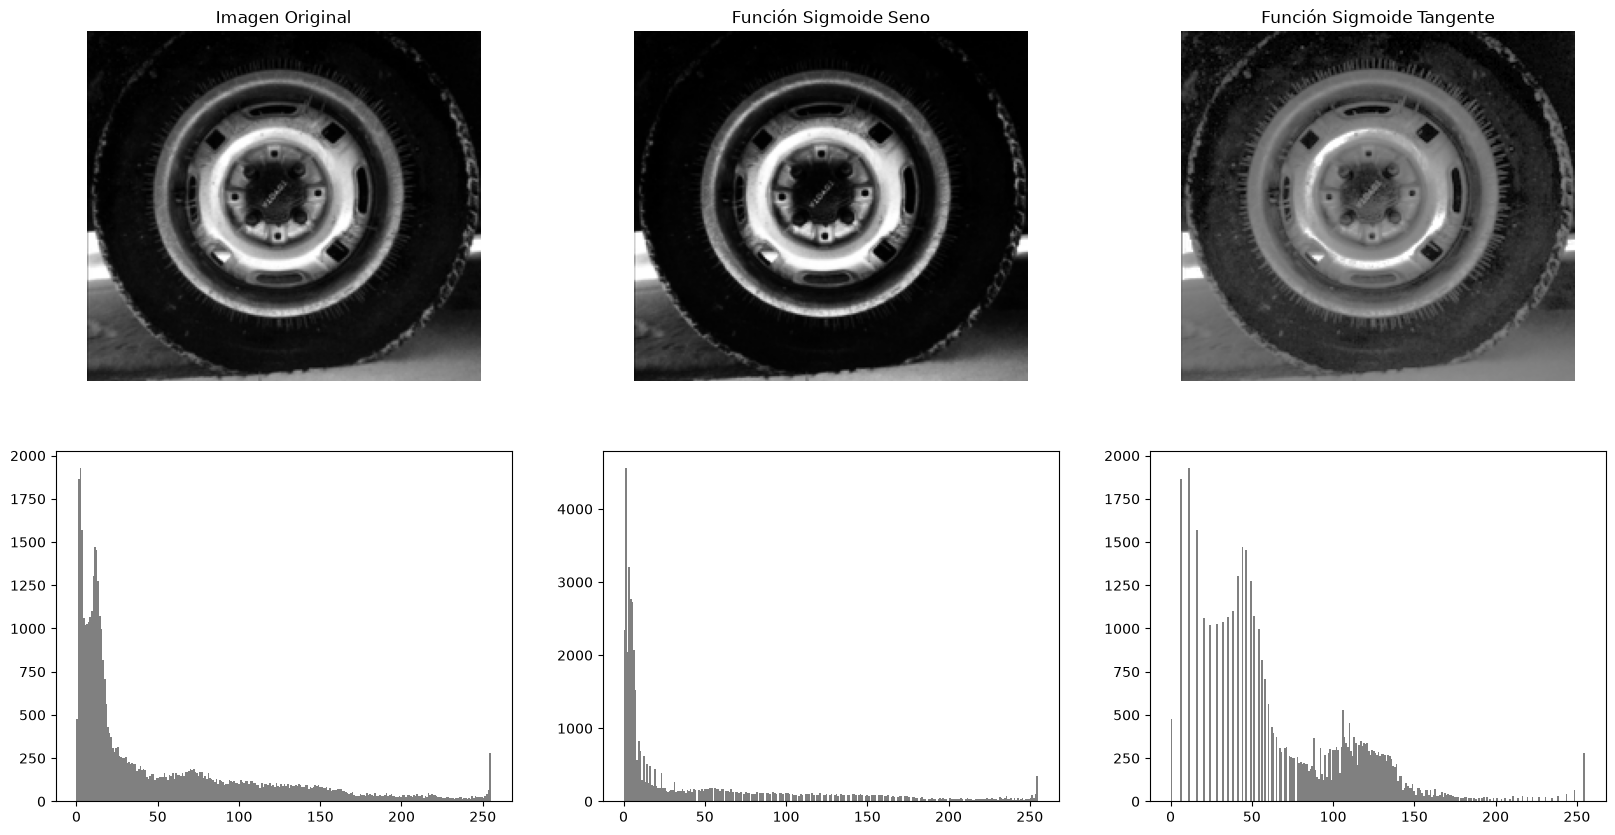

In [6]:
I_norm = I.astype(np.float32) / 255
alpha = 0.85

arg = alpha * np.pi * (I_norm - 0.5)

q1 = 255/2 * (1 + np.sin(arg) / np.sin(alpha*np.pi/2))
q2 = 255/2 * (1 + np.tan(arg) / np.tan(alpha*np.pi/2))

Isen = np.clip(np.round(q1), 0, 255).astype(np.uint8)
Itan = np.clip(np.round(q2), 0, 255).astype(np.uint8)

plt.figure(figsize=(20,10))
plt.subplot(2, 3, 1)
plt.imshow(I, cmap="gray", vmin= 0, vmax=255)
plt.title("Imagen Original")
plt.axis("off")

plt.subplot(2, 3, 2)
plt.imshow(Isen, cmap="gray", vmin= 0, vmax=255)
plt.title("Función Sigmoide Seno")
plt.axis("off")

plt.subplot(2, 3, 3)
plt.imshow(Itan, cmap="gray", vmin= 0, vmax=255)
plt.title("Función Sigmoide Tangente")
plt.axis("off")

plt.subplot(2, 3, 4)
plt.hist(I.ravel(), bins=256, range=(0,255), color="gray")

plt.subplot(2, 3, 5)
plt.hist(Isen.ravel(), bins=256, range=(0,255), color="gray")

plt.subplot(2, 3, 6)
plt.hist(Itan.ravel(), bins=256, range=(0,255), color="gray")
plt.show()

La sigmoide seno aumenta el contraste de los tonos medios, comprimiendo las sombras y las luces.
Como vemos en la imagen vemos con mas detalles las llantas y mas oscuro el neumático

La sigmoide tangente: aumenta el contraste en los extremos comprimiendo los tonos medios.
Vemos mas detalle en los neumátivos que en las zonas mas claras de la llantas, mientras que el resto se ve mas plano.

## Segunda Parte. Ecualización uniforme o igualación de histograma y modos de aplicación. 

### Ecualización global

3. Implementar una función para ecualizar de forma uniforme una imagen. La función
recibe como entrada una imagen de intensidad I y devuelve como salida la imagen Ieq
ecualizada de forma uniforme. Se deben implementar tres versiones de la función
(ecualizar_imagen_v1, ecualizar_imagen_v2 y ecualizar_imagen_v3, todas definidas en
Visión por Computador. 4º Grado en Ingeniería Informática - DIESIA – ETSI - UHU
Práctica 3 – Manipulación de contraste en imágenes digitales: operaciones locales y globales basadas en
procesamiento de histogramas”
3 de 7
el fichero Python funciones_ecualizar_imagen.py) de acuerdo con los siguientes
criterios: 


V1. Recorrido a nivel de píxel: implementación basada en el recorrido píxel a píxel de
la imagen y calcular la función de transformación para cada píxel para generar la
imagen de salida

In [ ]:
def ecualizar_imagen_v1(I):
    filas, columnas = I.shape
    N = filas * columnas

    h = np.histogram(I, bins=256, range=(0, 256))[0]

    Ieq = np.zeros_like(I, dtype=np.uint8)
    for i in range(filas):
        for j in range(columnas):
            p = int(I[i, j])
            Ieq[i, j] = np.round(255 * h[:p + 1].sum() / N)
    return Ieq

V2. Tabla de transformación + indexación vectorizada: calcular la función de
transformación para cada nivel de gris posible y aplicarla de forma global sobre la
imagen para generar la imagen de salida. 

In [ ]:
def ecualizar_imagen_v2(I):
    L = 256
    N = I.size

    h = np.histogram(I, bins=L, range=(0,L))

    lut = np.zeros(L, dtype=np.uint8)
    acumulado = 0
    for g in range(L):
        acumulado += h[g]
        lut[g] = np.round((L - 1) / N * acumulado)
    return lut[I]

V3. Recorrido por nivel de gris: realizar el cálculo de la función de transformación
para cada nivel de gris posible y, haciendo un barrido en los 256 posibles niveles de
gris, aplicarla para generar la imagen de salida. 

In [8]:
def ecualizar_imagen_v3(I):
    L = 256
    N = I.size

    h = np.histogram(I, bins=L, range=(0,L)[0])
    Ieq = np.zeros_like(I, dtype=np.uint8)
    acumulado = 0
    for g in range(L):
        acumulado += h[g]
        nuevo = np.round((L - 1) / N * acumulado)
        Ieq[I == g] = nuevo
    return Ieq

45000